# FIT5215 / FIT3181 Assignment 1 - Kaggle Starter Notebook

This notebook provides a complete, deliberately simple workflow: download the training data, load the hidden-label Kaggle test set, create a validation split, train a starter CNN, and write a valid Kaggle submission.

The starter notebook is intended to run in **Google Colab with a GPU runtime**. Improve the data augmentation, model architecture, optimization, and validation procedure for your own submission.

## Before you start

1. In Colab, select **Runtime → Change runtime type → GPU**.
2. Make your own copy of this notebook.
3. On the competition **Data** tab, download `test_set.zip` and upload it to the Colab Files pane. When extracted, it creates a `test_set` folder containing the `test_dataset` image folder and the sample submission template `my_solution.csv`.

   **If your computer automatically decompresses the file downloaded from Kaggle, compress the complete extracted `test_set` folder again, name the new archive `test_set.zip`, and upload that ZIP file to Colab.**

4. The labelled training set is downloaded separately from Google Drive. Use the [primary training archive](https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing), or manually switch to the [backup training archive](https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing) if the primary link is unavailable.

The release contains **9,466 labelled training images across 20 classes** and **11,681 unlabelled 64×64 test images**. The submission template contains the columns `ID,Label`. Use only the provided training labels and follow the assignment and competition rules.

In [3]:
%pip install -q "open_clip_torch>=3.0,<4.0" scikit-learn

from __future__ import annotations

import gc
import os
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from IPython.display import display
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.utils import make_grid

SEED = 2026
N_FOLDS = 5

ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd()
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset.zip'
TRAIN_DIR = ROOT / 'FIT5215_Dataset'
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'


def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Faster fixed-size training on A100.
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False

    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True


seed_everything(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

if torch.cuda.is_available():
    torch.set_float32_matmul_precision('high')

print('Working directory:', ROOT)
print('PyTorch:', torch.__version__)
print('Device:', device)

if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Warning: training will be much slower without a GPU runtime.')


Working directory: /content
PyTorch: 2.11.0+cu128
Device: cuda
GPU: NVIDIA A100-SXM4-80GB


## 1. Download the labelled training set

Run the primary download below. If that link is unavailable, comment it out and uncomment the backup download. Both commands save the archive with the same filename.

In [4]:
# Primary download
#!gdown --fuzzy 'https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing' -O Animals_Dataset.zip

# Backup download: use this only if the primary link is unavailable.
# !gdown --fuzzy 'https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing' -O Animals_Dataset.zip

!unzip -q -o Animals_Dataset_v2.zip
assert TRAIN_DIR.is_dir(), f'Training folder not found: {TRAIN_DIR}'
print('Training data ready:', TRAIN_DIR)

Training data ready: /content/FIT5215_Dataset


## 2. Load the Kaggle test data and submission template

Upload `test_set.zip` to the Colab Files pane. It must extract into the same layout as the Kaggle download:

```text
test_set.zip
└── test_set/
    ├── test_dataset/
    │   ├── 00000_animal.jpeg
    │   └── ...
    └── my_solution.csv
```

**If your computer automatically decompresses the Kaggle download, compress the complete extracted `test_set` folder again, name the archive `test_set.zip`, and then upload it to Colab.** Keep the names and folder structure unchanged.

In [5]:
!unzip -q -o test_set.zip -d /content

In [6]:
EXPECTED_TEST_IMAGES = 11681
if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    assert TEST_ARCHIVE.is_file(), 'Upload test_set.zip to the Colab Files pane before continuing.'
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)
assert TEST_PACKAGE_DIR.is_dir(), 'The ZIP must contain a top-level folder named test_set.'
assert TEST_DIR.is_dir(), 'The test_set folder must contain the test_dataset image folder.'
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), 'Test image IDs must run from 0 to 11680.'
assert SUBMISSION_TEMPLATE.is_file(), 'The test_set folder must contain my_solution.csv.'
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())

Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


## 3. Build training, validation, and test datasets

The split is stratified so every class is represented in both training and validation. Training augmentation is intentionally mild because the Kaggle images are only 64×64. Validation and test preprocessing are deterministic.

In [7]:
EXPECTED_CLASS_NAMES = ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']
CLASS_NAME_CORRECTIONS = {'butterfiles': 'butterflies'}
MEAN = (0.48145466, 0.4578275, 0.40821073)
STD = (0.26862954, 0.26130258, 0.27577711)

class RandomLowResolution:

    def __init__(self, sizes=(48, 56, 64, 72, 80), final_size=64):
        self.sizes = tuple(sizes)
        self.final_size = int(final_size)

    def __call__(self, image):
        low_size = random.choice(self.sizes)
        image = TF.resize(image, [low_size, low_size], interpolation=InterpolationMode.BICUBIC, antialias=True)
        image = TF.resize(image, [self.final_size, self.final_size], interpolation=InterpolationMode.BICUBIC, antialias=True)
        return image
train_transform = transforms.Compose([RandomLowResolution(sizes=(48, 56, 64, 72, 80), final_size=64), transforms.RandomResizedCrop(64, scale=(0.78, 1.0), ratio=(0.86, 1.14), interpolation=InterpolationMode.BICUBIC), transforms.RandomHorizontalFlip(p=0.5), transforms.RandomRotation(degrees=9, interpolation=InterpolationMode.BILINEAR), transforms.RandomApply([transforms.ColorJitter(brightness=0.16, contrast=0.16, saturation=0.16, hue=0.025)], p=0.75), transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.14), transforms.RandAugment(num_ops=2, magnitude=5), transforms.Resize((378, 378), interpolation=InterpolationMode.BICUBIC), transforms.ToTensor(), transforms.Normalize(MEAN, STD), transforms.RandomErasing(p=0.1, scale=(0.02, 0.1), ratio=(0.5, 2.0))])
evaluation_transform = transforms.Compose([transforms.Resize((64, 64), interpolation=InterpolationMode.BICUBIC), transforms.Resize((378, 378), interpolation=InterpolationMode.BICUBIC), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
index_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names = [CLASS_NAME_CORRECTIONS.get(name, name) for name in index_dataset.classes]
if class_names != EXPECTED_CLASS_NAMES:
    raise RuntimeError(f'Unexpected training class order: {class_names}')
targets = np.asarray(index_dataset.targets, dtype=np.int64)
all_indices = np.arange(len(index_dataset))
training_augmented = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
training_evaluation = datasets.ImageFolder(TRAIN_DIR, transform=evaluation_transform)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_splits = list(skf.split(all_indices, targets))

class KaggleTestDataset(Dataset):

    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        test_id = int(path.name.split('_', 1)[0])
        with Image.open(path) as image:
            tensor = self.transform(image.convert('RGB'))
        return (tensor, test_id)
test_dataset = KaggleTestDataset(test_paths, evaluation_transform)
print('Classes:', class_names)
print('Total labelled images:', len(index_dataset))
for fold_number, (fold_train_indices, fold_validation_indices) in enumerate(fold_splits, start=1):
    print(f'Fold {fold_number}: train={len(fold_train_indices):,}, validation={len(fold_validation_indices):,}')

Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']
Total labelled images: 9466
Fold 1: train=7,572, validation=1,894
Fold 2: train=7,573, validation=1,893
Fold 3: train=7,573, validation=1,893
Fold 4: train=7,573, validation=1,893
Fold 5: train=7,573, validation=1,893


In [8]:
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 1
NUM_WORKERS = min(4, os.cpu_count() or 1)
pin_memory = device.type == 'cuda'

def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(dataset, batch_size, shuffle, seed):
    generator = torch.Generator().manual_seed(seed)
    loader_arguments = {'dataset': dataset, 'batch_size': batch_size, 'shuffle': shuffle, 'generator': generator if shuffle else None, 'worker_init_fn': seed_worker, 'num_workers': NUM_WORKERS, 'pin_memory': pin_memory}
    if NUM_WORKERS > 0:
        loader_arguments['persistent_workers'] = True
        loader_arguments['prefetch_factor'] = 4
    return DataLoader(**loader_arguments)
example_train_indices = fold_splits[0][0]
example_validation_indices = fold_splits[0][1]
train_evaluation_dataset = Subset(training_evaluation, example_train_indices.tolist())
validation_dataset = Subset(training_evaluation, example_validation_indices.tolist())
train_evaluation_loader = make_loader(train_evaluation_dataset, BATCH_SIZE, False, SEED)
validation_loader = make_loader(validation_dataset, BATCH_SIZE, False, SEED)
test_loader = make_loader(test_dataset, BATCH_SIZE, False, SEED)
print(f'Train example fold: {len(train_evaluation_dataset):,}')
print(f'Validation example fold: {len(validation_dataset):,}')
print(f'Test: {len(test_dataset):,}')

Train example fold: 7,572
Validation example fold: 1,894
Test: 11,681


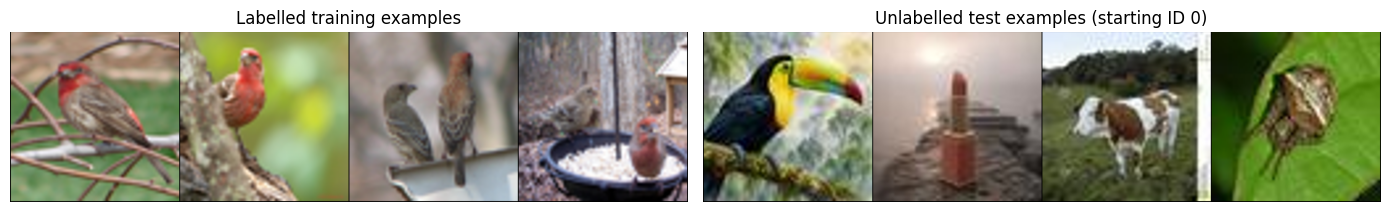

Example training label: birds


In [9]:
def denormalize(batch: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)
images, labels = next(iter(train_evaluation_loader))
test_images, displayed_test_ids = next(iter(test_loader))
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(make_grid(denormalize(images[:32]), nrow=8).permute(1, 2, 0))
axes[0].set_title('Labelled training examples')
axes[0].axis('off')
axes[1].imshow(make_grid(denormalize(test_images[:32]), nrow=8).permute(1, 2, 0))
axes[1].set_title(f'Unlabelled test examples (starting ID {int(displayed_test_ids[0])})')
axes[1].axis('off')
figure.tight_layout()
plt.show()
print('Example training label:', class_names[int(labels[0])])

## 4. Define a starter CNN

This compact network is a starting point, not a target solution. You are expected to make and justify your own improvements within the assignment rules.

In [10]:
BACKBONE_NAME = 'hf-hub:apple/DFN5B-CLIP-ViT-H-14-378'
HEAD_DROPOUT = 0.1

class CLIPClassifier(nn.Module):

    def __init__(self, num_classes: int):
        super().__init__()
        pretrained_clip, _, pretrained_transform = open_clip.create_model_and_transforms(BACKBONE_NAME)
        normalization = next((transform for transform in pretrained_transform.transforms if isinstance(transform, transforms.Normalize)))
        assert np.allclose(normalization.mean, MEAN)
        assert np.allclose(normalization.std, STD)
        self.features = pretrained_clip.visual
        feature_dim = int(self.features.output_dim)
        self.features.requires_grad_(False)
        self.features.eval()
        self.classifier = nn.Sequential(nn.LayerNorm(feature_dim), nn.Dropout(p=HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        del pretrained_clip

    def train(self, mode=True):
        super().train(mode)
        if not any((parameter.requires_grad for parameter in self.features.parameters())):
            self.features.eval()
        return self

    def forward(self, images):
        if images.shape[-2:] != (378, 378):
            images = F.interpolate(images, size=(378, 378), mode='bicubic', align_corners=False, antialias=True)
        features = self.features(images)
        return self.classifier(features.float())
model = CLIPClassifier(num_classes=len(class_names)).to(device)
trainable_parameters = sum((parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print(model.classifier)
print(f'Trainable parameters before fine-tuning: {trainable_parameters:,}')
del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

open_clip_config.json:   0%|          | 0.00/735 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 3.95GB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

Sequential(
  (0): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  (1): Dropout(p=0.1, inplace=False)
  (2): Linear(in_features=1024, out_features=20, bias=True)
)
Trainable parameters before fine-tuning: 22,548


## 5. Train and select the best validation checkpoint

Only validation performance is used for model selection. The Kaggle test set remains unlabelled and is used once for final prediction.

In [11]:
LOSS_FUNCTION = nn.CrossEntropyLoss(label_smoothing=0.02)
HEAD_EPOCHS = 4
FINE_TUNE_EPOCHS = 6
HEAD_LEARNING_RATE = 0.001
LATE_BLOCK_LEARNING_RATE = 2e-06
CLASSIFIER_LEARNING_RATE = 1e-05
LAYER_DECAY = 0.88
WEIGHT_DECAY = 0.0001

def run_epoch(model, loader, loss_function, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    amp_enabled = device.type == 'cuda'

    if training:
        optimizer.zero_grad(set_to_none=True)

    for batch_number, (images, labels) in enumerate(loader, start=1):
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        labels = labels.to(device=device, dtype=torch.long, non_blocking=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=amp_enabled):
                logits = model(images)
                full_loss = loss_function(logits, labels)

            if training:
                backward_loss = full_loss / GRAD_ACCUM_STEPS
                scaler.scale(backward_loss).backward()
                should_step = batch_number % GRAD_ACCUM_STEPS == 0 or batch_number == len(loader)

                if should_step:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)

        batch_size = labels.size(0)
        total_loss += full_loss.item() * batch_size
        total_correct += int((logits.argmax(dim=1) == labels).sum())
        total_examples += batch_size
    return (total_loss / total_examples, total_correct / total_examples)

def make_fine_tune_optimizer(model):
    model.features.requires_grad_(True)
    model.classifier.requires_grad_(True)
    blocks = list(model.features.transformer.resblocks)
    parameter_groups = []
    block_parameter_ids = set()
    number_of_blocks = len(blocks)

    for block_index, block in enumerate(blocks):
        exponent = number_of_blocks - 1 - block_index
        block_learning_rate = LATE_BLOCK_LEARNING_RATE * LAYER_DECAY ** exponent
        parameters = list(block.parameters())
        block_parameter_ids.update((id(parameter) for parameter in parameters))
        parameter_groups.append({'params': parameters, 'lr': block_learning_rate})

    other_encoder_parameters = [parameter for parameter in model.features.parameters() if id(parameter) not in block_parameter_ids]
    earliest_learning_rate = LATE_BLOCK_LEARNING_RATE * LAYER_DECAY ** number_of_blocks
    parameter_groups.append({'params': other_encoder_parameters, 'lr': earliest_learning_rate})
    parameter_groups.append({'params': model.classifier.parameters(), 'lr': CLASSIFIER_LEARNING_RATE})
    return torch.optim.AdamW(parameter_groups, weight_decay=WEIGHT_DECAY)

def train_one_fold(fold_number, train_indices, validation_indices):
    fold_seed = SEED + fold_number * 100
    seed_everything(fold_seed)
    train_dataset = Subset(training_augmented, train_indices.tolist())
    validation_dataset = Subset(training_evaluation, validation_indices.tolist())
    train_loader = make_loader(train_dataset, BATCH_SIZE, True, fold_seed)
    validation_loader = make_loader(validation_dataset, BATCH_SIZE, False, fold_seed)
    model = CLIPClassifier(num_classes=len(class_names)).to(device)
    fold_history = []

    head_optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=HEAD_LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    head_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(head_optimizer, T_max=max(1, HEAD_EPOCHS), eta_min=1e-06)
    head_scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    best_head_score = (-1.0, float('-inf'))
    best_head_classifier = None

    for epoch in range(1, HEAD_EPOCHS + 1):
        train_loss, train_accuracy = run_epoch(model, train_loader, LOSS_FUNCTION, head_optimizer, head_scaler)
        validation_loss, validation_accuracy = run_epoch(model, validation_loader, LOSS_FUNCTION)
        fold_history.append({'fold': fold_number, 'epoch': epoch, 'stage': 'head', 'train_loss': train_loss, 'train_accuracy': train_accuracy, 'validation_loss': validation_loss, 'validation_accuracy': validation_accuracy})
        score = (validation_accuracy, -validation_loss)

        if score > best_head_score:
            best_head_score = score
            best_head_classifier = {name: tensor.detach().cpu().clone() for name, tensor in model.classifier.state_dict().items()}
        head_scheduler.step()
        print(f'Fold {fold_number} | Head {epoch:02d}/{HEAD_EPOCHS:02d} | train {train_accuracy:.2%} | val {validation_accuracy:.2%}')

    model.classifier.load_state_dict(best_head_classifier)

    fine_optimizer = make_fine_tune_optimizer(model)
    fine_scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    warmup = torch.optim.lr_scheduler.LinearLR(fine_optimizer, start_factor=0.25, end_factor=1.0, total_iters=1)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(fine_optimizer, T_max=max(1, FINE_TUNE_EPOCHS - 1), eta_min=1e-08)
    fine_scheduler = torch.optim.lr_scheduler.SequentialLR(fine_optimizer, schedulers=[warmup, cosine], milestones=[1])
    best_score = (-1.0, float('-inf'))
    best_epoch = 0
    checkpoint_path = ROOT / f'fold_{fold_number}_best.pt'

    for fine_epoch in range(1, FINE_TUNE_EPOCHS + 1):
        train_loss, train_accuracy = run_epoch(model, train_loader, LOSS_FUNCTION, fine_optimizer, fine_scaler)
        validation_loss, validation_accuracy = run_epoch(model, validation_loader, LOSS_FUNCTION)
        graph_epoch = HEAD_EPOCHS + fine_epoch
        fold_history.append({'fold': fold_number, 'epoch': graph_epoch, 'stage': 'fine', 'train_loss': train_loss, 'train_accuracy': train_accuracy, 'validation_loss': validation_loss, 'validation_accuracy': validation_accuracy})
        score = (validation_accuracy, -validation_loss)

        if score > best_score:
            best_score = score
            best_epoch = fine_epoch
            best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
            torch.save(best_state, checkpoint_path)

            del best_state
            gc.collect()
        fine_scheduler.step()
        print(f'Fold {fold_number} | Fine {fine_epoch:02d}/{FINE_TUNE_EPOCHS:02d} | train {train_accuracy:.2%} | val {validation_accuracy:.2%} | val loss {validation_loss:.4f}')

    model.load_state_dict(torch.load(checkpoint_path, map_location='cpu'))
    model.to(device)
    final_validation_loss, final_validation_accuracy = run_epoch(model, validation_loader, LOSS_FUNCTION)
    result = {'fold': fold_number, 'best_epoch': best_epoch, 'validation_accuracy': final_validation_accuracy, 'validation_loss': final_validation_loss, 'checkpoint_path': str(checkpoint_path)}
    del model
    del train_loader
    del validation_loader
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return (result, pd.DataFrame(fold_history))

In [12]:
fold_results = []
fold_histories = []

for fold_number, (fold_train_indices, fold_validation_indices) in enumerate(fold_splits, start=1):
    print()
    print(f'STARTING FOLD {fold_number}/{N_FOLDS}')
    result, fold_history = train_one_fold(fold_number, fold_train_indices, fold_validation_indices)
    fold_results.append(result)
    fold_histories.append(fold_history)
    print(f"Fold {fold_number} complete | best fine epoch={result['best_epoch']} | val acc={result['validation_accuracy']:.2%} | val loss={result['validation_loss']:.4f}")

fold_results_frame = pd.DataFrame(fold_results)
display(fold_results_frame)

print('Mean fold validation accuracy:', f"{fold_results_frame['validation_accuracy'].mean():.2%}")

all_history = pd.concat(fold_histories, ignore_index=True)
history = all_history.groupby('epoch', as_index=False)[['train_loss', 'train_accuracy', 'validation_loss', 'validation_accuracy']].mean()

print()
print('Graph below shows the mean training and validation result across all 5 folds.')


STARTING FOLD 1/5
Fold 1 | Head 01/04 | train 95.95% | val 99.47%
Fold 1 | Head 02/04 | train 97.94% | val 99.58%
Fold 1 | Head 03/04 | train 98.35% | val 99.42%
Fold 1 | Head 04/04 | train 98.93% | val 99.47%
Fold 1 | Fine 01/06 | train 98.61% | val 99.74% | val loss 0.1789
Fold 1 | Fine 02/06 | train 98.97% | val 99.68% | val loss 0.1666
Fold 1 | Fine 03/06 | train 99.04% | val 99.74% | val loss 0.1643
Fold 1 | Fine 04/06 | train 99.09% | val 99.79% | val loss 0.1616
Fold 1 | Fine 05/06 | train 99.21% | val 99.74% | val loss 0.1614
Fold 1 | Fine 06/06 | train 99.18% | val 99.74% | val loss 0.1612
Fold 1 complete | best fine epoch=4 | val acc=99.79% | val loss=0.1616

STARTING FOLD 2/5
Fold 2 | Head 01/04 | train 96.14% | val 99.47%
Fold 2 | Head 02/04 | train 97.97% | val 99.63%
Fold 2 | Head 03/04 | train 98.56% | val 99.52%
Fold 2 | Head 04/04 | train 98.77% | val 99.68%
Fold 2 | Fine 01/06 | train 99.02% | val 99.68% | val loss 0.1774
Fold 2 | Fine 02/06 | train 99.12% | val 99.6

,fold,best_epoch,validation_accuracy,validation_loss,checkpoint_path
0,1,4,0.997888,0.161550,/content/fold_1_best.pt
1,2,5,0.997359,0.165402,/content/fold_2_best.pt
2,3,4,0.996302,0.167396,/content/fold_3_best.pt
3,4,6,0.996830,0.164172,/content/fold_4_best.pt
4,5,6,0.996302,0.167957,/content/fold_5_best.pt


Mean fold validation accuracy: 99.69%

Graph below shows the mean training and validation result across all 5 folds.


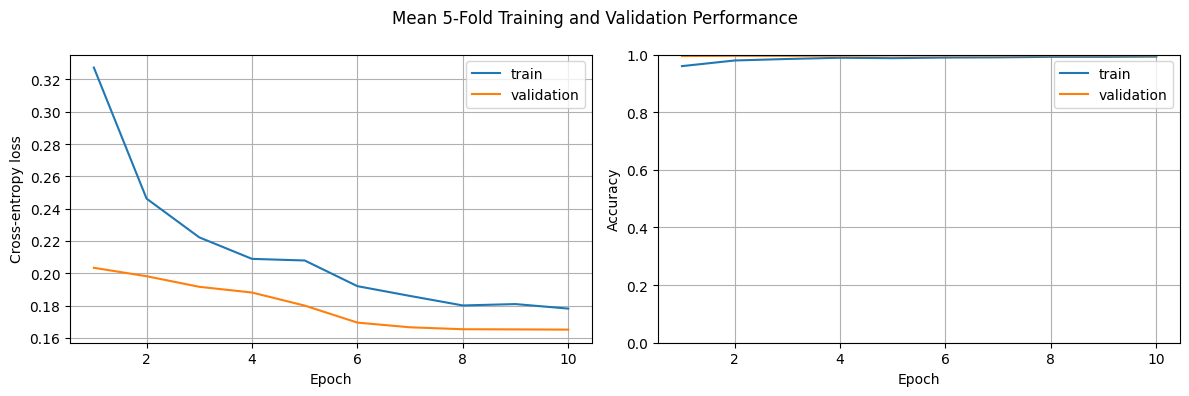

In [13]:
figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(12, 4))
loss_axis.plot(history['epoch'], history['train_loss'], label='train')
loss_axis.plot(history['epoch'], history['validation_loss'], label='validation')
loss_axis.set(xlabel='Epoch', ylabel='Cross-entropy loss')
loss_axis.grid(True)
loss_axis.legend()
accuracy_axis.plot(history['epoch'], history['train_accuracy'], label='train')
accuracy_axis.plot(history['epoch'], history['validation_accuracy'], label='validation')
accuracy_axis.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1))
accuracy_axis.grid(True)
accuracy_axis.legend()
figure.suptitle('Mean 5-Fold Training and Validation Performance')
figure.tight_layout()
plt.show()

## 6. Predict the test set and create `submission.csv`

Kaggle expects exactly 11,681 rows with the string columns `ID,Label`. Prediction IDs are carried through the data loader and merged into the public template, so batching cannot silently reorder the submission.

In [14]:
@torch.inference_mode()
def predict_probabilities(checkpoint_path):
    model = CLIPClassifier(num_classes=len(class_names)).to(device)
    model.load_state_dict(torch.load(checkpoint_path, map_location='cpu'))
    model.to(device)
    model.eval()
    predicted_ids = []
    all_probabilities = []

    for images, image_ids in test_loader:
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)

        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(images)
        probabilities = torch.softmax(logits.float(), dim=1)
        all_probabilities.append(probabilities.cpu())
        predicted_ids.extend(image_ids.tolist())
    all_probabilities = torch.cat(all_probabilities, dim=0)
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return (predicted_ids, all_probabilities)

ensemble_probabilities = None
predicted_ids = None

for fold_result in fold_results:
    print(f"Predicting with fold {fold_result['fold']}...")
    fold_ids, fold_probabilities = predict_probabilities(fold_result['checkpoint_path'])

    if predicted_ids is None:
        predicted_ids = fold_ids
        ensemble_probabilities = fold_probabilities / N_FOLDS

    else:
        assert predicted_ids == fold_ids

        ensemble_probabilities += fold_probabilities / N_FOLDS
predicted_indices = ensemble_probabilities.argmax(dim=1).tolist()
prediction_frame = pd.DataFrame({'ID': predicted_ids, 'Label': [class_names[index] for index in predicted_indices]})

if prediction_frame['ID'].duplicated().any():
    raise RuntimeError('Predictions contain duplicate IDs.')

if set(prediction_frame['Label']) - set(EXPECTED_CLASS_NAMES):
    raise RuntimeError('Predictions contain an invalid class label.')
submission = submission_template[['ID']].merge(prediction_frame, on='ID', how='left', validate='one_to_one')

if submission.columns.tolist() != ['ID', 'Label']:
    raise RuntimeError('Submission must contain exactly ID,Label.')

if len(submission) != EXPECTED_TEST_IMAGES or submission['Label'].isna().any():
    raise RuntimeError('Submission rows do not match the test set.')

if submission['ID'].tolist() != list(range(EXPECTED_TEST_IMAGES)):
    raise RuntimeError('Submission IDs are not ordered from 0 to 11680.')

SUBMISSION_PATH = ROOT / 'submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False)
print('Submission:', SUBMISSION_PATH)
print('Rows:', len(submission))
display(submission.head())
display(submission['Label'].value_counts().sort_index())

Predicting with fold 1...
Predicting with fold 2...
Predicting with fold 3...
Predicting with fold 4...
Predicting with fold 5...
Submission: /content/submission.csv
Rows: 11681


,ID,Label
0,0,chickens
1,1,lipsticks
2,2,cows
3,3,spiders
4,4,dogs


,count
Label,
birds,166
bottles,323
breads,310
butterflies,932
cakes,377
cats,973
chickens,921
cows,1048
dogs,798


## 7. Submit and improve

Download `submission.csv`, open your cohort's Kaggle competition, choose **Submit Predictions**, and upload the CSV. Do not upload the unchanged `my_solution.csv` placeholder.

Useful next experiments include stronger but still mild augmentation, deeper model architectures, regularization, learning-rate schedules, class-balanced sampling, and permitted pretrained models. Keep the validation split fixed while comparing experiments, and preserve the exact test IDs and canonical string labels.

In [15]:
# Run this cell in Google Colab to download the completed submission.
try:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))
except ImportError:
    print(f'Not running in Colab. Submission is saved at {SUBMISSION_PATH}.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>